In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("scodepy/customer-support-intent-dataset")

print("Path to dataset files:", path)

100%|██████████| 60.0k/60.0k [00:00<00:00, 1.69MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/scodepy/customer-support-intent-dataset/versions/1


In [ ]:
import os
import glob
import pandas as pd

# Search for all CSV files in the dataset path
csv_files = glob.glob(os.path.join(path, '**/*.csv'), recursive=True)
print("Found CSV files:", csv_files)

# Read all CSV files into a list of DataFrames
dataframes = {}
for file_path in csv_files:
    filename = os.path.basename(file_path)
    df = pd.read_csv(file_path)
    dataframes[filename] = df
    print(f"{filename}: {df.shape[0]} rows, {df.shape[1]} columns")

Found CSV files: ['/root/.cache/kagglehub/datasets/scodepy/customer-support-intent-dataset/versions/1/Bitext_Sample_Customer_Service_Training_Dataset.csv', '/root/.cache/kagglehub/datasets/scodepy/customer-support-intent-dataset/versions/1/Bitext_Sample_Customer_Service_Testing_Dataset.csv', '/root/.cache/kagglehub/datasets/scodepy/customer-support-intent-dataset/versions/1/Bitext_Sample_Customer_Service_Validation_Dataset.csv']
Bitext_Sample_Customer_Service_Training_Dataset.csv: 6539 rows, 4 columns
Bitext_Sample_Customer_Service_Testing_Dataset.csv: 818 rows, 4 columns
Bitext_Sample_Customer_Service_Validation_Dataset.csv: 818 rows, 4 columns


In [ ]:
import os
import glob
import pandas as pd

# Find the CSV files again to ensure path is accessible
csv_files = glob.glob(os.path.join(path, '**/*.csv'), recursive=True)

# Print the column details for each file
for file_path in csv_files:
    filename = os.path.basename(file_path)
    df = pd.read_csv(file_path)
    print(f"=== File: {filename} ===")
    print(f"Columns: {list(df.columns)}")
    print(f"Shape: {df.shape}")
    print("Preview:")
    display(df.head(2))
    print("\n" + "="*40 + "\n")

=== File: Bitext_Sample_Customer_Service_Training_Dataset.csv ===
Columns: ['utterance', 'intent', 'category', 'tags']
Shape: (6539, 4)
Preview:


,utterance,intent,category,tags
0,would it be possible to cancel the order I made?,cancel_order,ORDER,BIP
1,cancelling order,cancel_order,ORDER,BK




=== File: Bitext_Sample_Customer_Service_Testing_Dataset.csv ===
Columns: ['utterance', 'intent', 'category', 'tags']
Shape: (818, 4)
Preview:


,utterance,intent,category,tags
0,I have a question about cancelling an order,cancel_order,ORDER,B
1,help canceling the order I have made,cancel_order,ORDER,B




=== File: Bitext_Sample_Customer_Service_Validation_Dataset.csv ===
Columns: ['utterance', 'intent', 'category', 'tags']
Shape: (818, 4)
Preview:


,utterance,intent,category,tags
0,I want help to cancel the order I have made,cancel_order,ORDER,B
1,where can I get information about order cancel...,cancel_order,ORDER,BIM


In [ ]:
# Merge or concatenate the datasets
# Since they typically contain matching intents, queries, or categories, we can concatenate them
# or merge based on common structures. Let's concatenate them together into a single DataFrame.
merged_df = pd.concat(dataframes.values(), ignore_index=True)
print(f"Merged DataFrame size: {merged_df.shape}")

# Display the first few rows
display(merged_df.head())

Merged DataFrame size: (8175, 4)


,utterance,intent,category,tags
0,would it be possible to cancel the order I made?,cancel_order,ORDER,BIP
1,cancelling order,cancel_order,ORDER,BK
2,I need assistance canceling the last order I h...,cancel_order,ORDER,B
3,problem with canceling the order I made,cancel_order,ORDER,B
4,I don't know how to cancel the order I made,cancel_order,ORDER,B


In [ ]:
# 1. Check for basic null / missing values
print("=== Null Value Counts ===")
print(merged_df.isnull().sum())

# 2. Check for empty strings or whitespaces in 'utterance'
empty_utterances = merged_df[merged_df['utterance'].str.strip() == '']
print(f"\nEmpty or whitespace-only utterances: {len(empty_utterances)}")

# 3. Explore the distribution of the target columns
print("\n=== Unique Intents ===")
print(f"Number of unique intents: {merged_df['intent'].nunique()}")
print(merged_df['intent'].value_counts().head(10))

print("\n=== Unique Categories ===")
print(f"Number of unique categories: {merged_df['category'].nunique()}")
print(merged_df['category'].value_counts())

# 4. Check 'tags' column to see if it is useful or noisy
print("\n=== Unique Tags (first 10) ===")
print(merged_df['tags'].value_counts().head(10))

=== Null Value Counts ===
utterance    0
intent       0
category     0
tags         0
dtype: int64

Empty or whitespace-only utterances: 0

=== Unique Intents ===
Number of unique intents: 27
intent
check_invoice              324
get_invoice                324
payment_issue              323
review                     315
track_refund               308
set_up_shipping_address    307
place_order                306
cancel_order               305
track_order                305
change_order               304
Name: count, dtype: int64

=== Unique Categories ===
Number of unique categories: 11
category
ACCOUNT             1774
ORDER               1220
REFUND               904
INVOICE              648
PAYMENT              620
FEEDBACK             613
SHIPPING_ADDRESS     604
DELIVERY             603
CONTACT              596
CANCELLATION_FEE     298
NEWSLETTER           295
Name: count, dtype: int64

=== Unique Tags (first 10) ===
tags
B       2395
BI      1066
BM       803
BIP      605
BL     

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Prepare the feature (X) and our three targets (y_intent, y_category, y_tags)
X = merged_df['utterance']
y_intent = merged_df['intent']
y_category = merged_df['category']
y_tags = merged_df['tags']

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train_intent, y_test_intent = train_test_split(X, y_intent, test_size=0.2, random_state=42)
_, _, y_train_category, y_test_category = train_test_split(X, y_category, test_size=0.2, random_state=42)
_, _, y_train_tags, y_test_tags = train_test_split(X, y_tags, test_size=0.2, random_state=42)

# Convert raw text to TF-IDF features
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Train features shape: {X_train_tfidf.shape}")
print(f"Test features shape: {X_test_tfidf.shape}")

Train features shape: (6540, 2979)
Test features shape: (1635, 2979)


In [ ]:
# Model 1: Intent Classifier
print("=== Training Model 1: Intent Classifier ===")
model_intent = LogisticRegression(max_iter=1000, random_state=42)
model_intent.fit(X_train_tfidf, y_train_intent)
y_pred_intent = model_intent.predict(X_test_tfidf)
intent_acc = accuracy_score(y_test_intent, y_pred_intent)
print(f"Intent Classifier Accuracy: {intent_acc:.4f}\n")
print(classification_report(y_test_intent, y_pred_intent))

=== Training Model 1: Intent Classifier ===
Intent Classifier Accuracy: 0.9908

                          precision    recall  f1-score   support

            cancel_order       0.97      1.00      0.98        64
            change_order       1.00      0.95      0.97        57
 change_shipping_address       0.97      0.98      0.98        65
  check_cancellation_fee       0.97      1.00      0.98        56
           check_invoice       1.00      1.00      1.00        76
   check_payment_methods       1.00      1.00      1.00        57
     check_refund_policy       1.00      0.97      0.98        63
               complaint       1.00      1.00      1.00        72
contact_customer_service       1.00      1.00      1.00        57
     contact_human_agent       1.00      1.00      1.00        53
          create_account       1.00      0.93      0.97        60
          delete_account       1.00      1.00      1.00        57
        delivery_options       1.00      1.00      1.00      

In [ ]:
# Model 2: Category Classifier
print("=== Training Model 2: Category Classifier ===")
model_category = LogisticRegression(max_iter=1000, random_state=42)
model_category.fit(X_train_tfidf, y_train_category)
y_pred_category = model_category.predict(X_test_tfidf)
category_acc = accuracy_score(y_test_category, y_pred_category)
print(f"Category Classifier Accuracy: {category_acc:.4f}\n")
print(classification_report(y_test_category, y_pred_category))

=== Training Model 2: Category Classifier ===
Category Classifier Accuracy: 0.9982

                  precision    recall  f1-score   support

         ACCOUNT       0.99      1.00      1.00       355
CANCELLATION_FEE       1.00      1.00      1.00        56
         CONTACT       1.00      1.00      1.00       110
        DELIVERY       1.00      1.00      1.00       116
        FEEDBACK       1.00      1.00      1.00       126
         INVOICE       1.00      1.00      1.00       134
      NEWSLETTER       1.00      1.00      1.00        59
           ORDER       1.00      1.00      1.00       260
         PAYMENT       1.00      0.99      1.00       125
          REFUND       1.00      0.99      1.00       173
SHIPPING_ADDRESS       1.00      0.99      1.00       121

        accuracy                           1.00      1635
       macro avg       1.00      1.00      1.00      1635
    weighted avg       1.00      1.00      1.00      1635



In [ ]:
# Model 3: Tags Classifier
print("=== Training Model 3: Tags Classifier ===")
model_tags = LogisticRegression(max_iter=1000, random_state=42)
model_tags.fit(X_train_tfidf, y_train_tags)
y_pred_tags = model_tags.predict(X_test_tfidf)
tags_acc = accuracy_score(y_test_tags, y_pred_tags)
print(f"Tags Classifier Accuracy: {tags_acc:.4f}\n")
# Display top classes classification report to avoid overwhelming output
print(classification_report(y_test_tags, y_pred_tags, labels=list(y_train_tags.value_counts().index[:10])))

=== Training Model 3: Tags Classifier ===
Tags Classifier Accuracy: 0.7450

              precision    recall  f1-score   support

           B       0.75      0.98      0.85       467
          BI       0.72      0.94      0.81       210
          BM       0.88      0.97      0.92       180
         BIP       0.94      0.99      0.96       121
          BL       0.37      0.51      0.43        81
         BIM       0.98      0.79      0.87        61
          BE       0.62      0.84      0.72        57
         BLQ       0.51      0.47      0.49        57
        BIMP       0.92      0.82      0.87        40
         BIL       0.55      0.16      0.25        37

   micro avg       0.74      0.88      0.81      1311
   macro avg       0.72      0.75      0.72      1311
weighted avg       0.75      0.88      0.80      1311



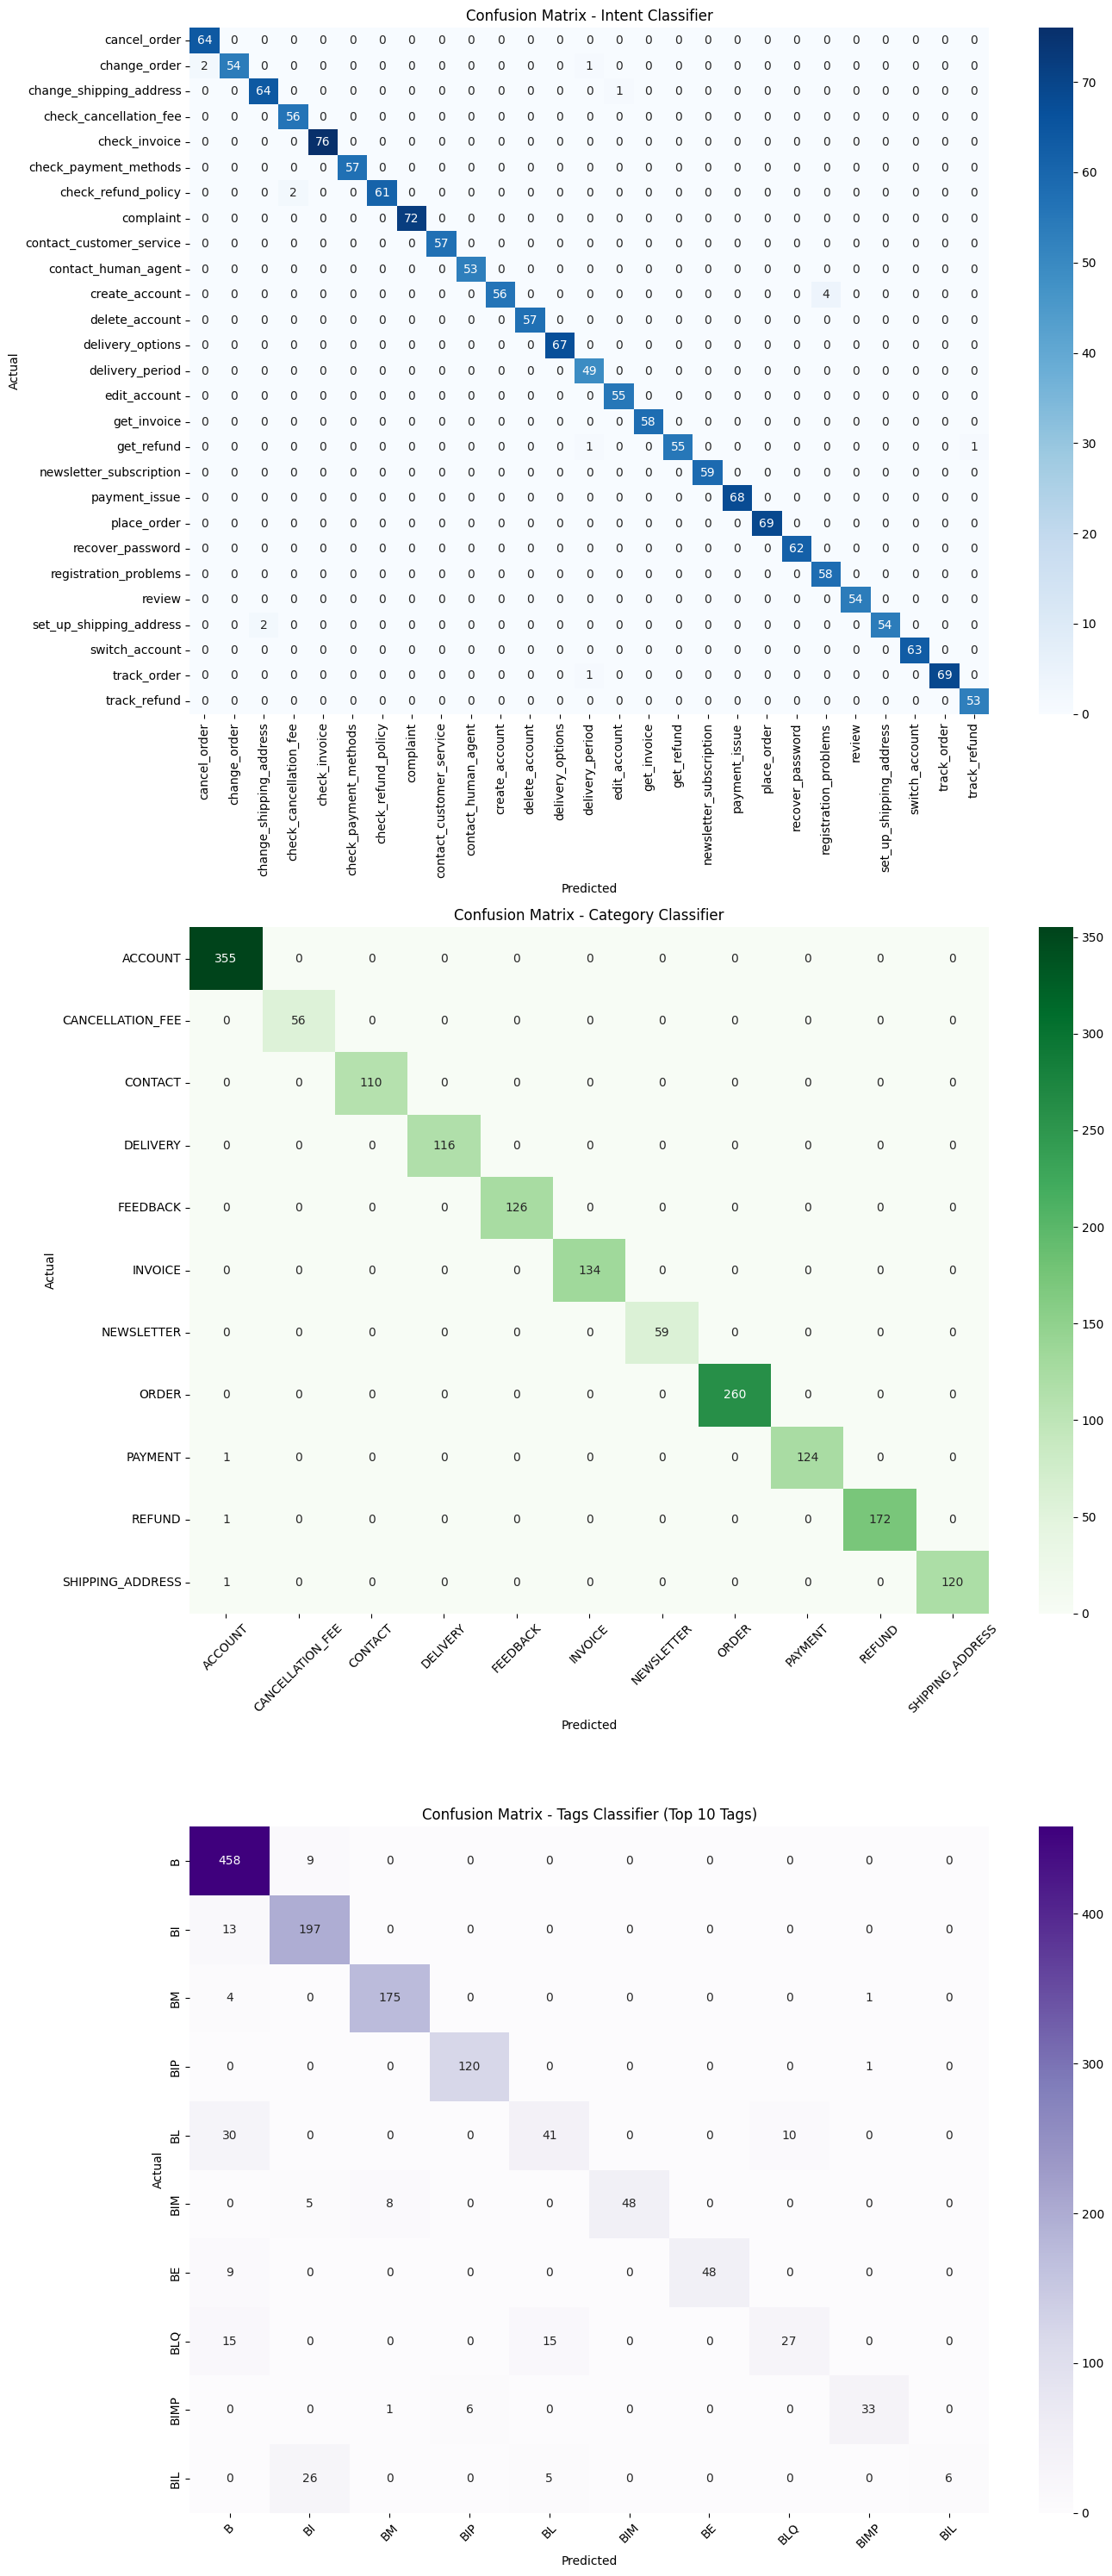

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Configure plots
fig, axes = plt.subplots(3, 1, figsize=(14, 30))

# 1. Intent Confusion Matrix (Top 15 classes for readability)
unique_intents = list(model_intent.classes_)
cm_intent = confusion_matrix(y_test_intent, y_pred_intent, labels=unique_intents)
# We'll plot the entire matrix, but with a size that fits
sns.heatmap(cm_intent, annot=True, fmt='d', cmap='Blues',
            xticklabels=unique_intents, yticklabels=unique_intents, ax=axes[0])
axes[0].set_title('Confusion Matrix - Intent Classifier')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].tick_params(axis='x', rotation=90)

# 2. Category Confusion Matrix
unique_categories = list(model_category.classes_)
cm_category = confusion_matrix(y_test_category, y_pred_category, labels=unique_categories)
sns.heatmap(cm_category, annot=True, fmt='d', cmap='Greens',
            xticklabels=unique_categories, yticklabels=unique_categories, ax=axes[1])
axes[1].set_title('Confusion Matrix - Category Classifier')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
axes[1].tick_params(axis='x', rotation=45)

# 3. Tags Confusion Matrix (Top 10 classes to avoid clutter)
top_tags = list(y_train_tags.value_counts().index[:10])
cm_tags = confusion_matrix(y_test_tags, y_pred_tags, labels=top_tags)
sns.heatmap(cm_tags, annot=True, fmt='d', cmap='Purples',
            xticklabels=top_tags, yticklabels=top_tags, ax=axes[2])
axes[2].set_title('Confusion Matrix - Tags Classifier (Top 10 Tags)')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Let's print out the specific misclassified examples to draw deep inferences
def print_misclassifications(y_true, y_pred, X_text, name, limit=5):
    misclassified = [(text, true, pred) for text, true, pred in zip(X_text, y_true, y_pred) if true != pred]
    print(f"\n=== Misclassifications for {name} (Total: {len(misclassified)}) ===")
    for i, (text, true, pred) in enumerate(misclassified[:limit]):
        print(f"{i+1}. Text: \"{text}\"\n   True Label: {true} | Predicted: {pred}\n")

print_misclassifications(y_test_intent, y_pred_intent, X_test, "Intent Classifier")
print_misclassifications(y_test_category, y_pred_category, X_test, "Category Classifier")
print_misclassifications(y_test_tags, y_pred_tags, X_test, "Tags Classifier")


=== Misclassifications for Intent Classifier (Total: 15) ===
1. Text: "invalid shipping address"
   True Label: set_up_shipping_address | Predicted: change_shipping_address

2. Text: "when will my order arrive"
   True Label: track_order | Predicted: delivery_period

3. Text: "I'm not one of ur mwmbers I'm trying to sign up"
   True Label: create_account | Predicted: registration_problems

4. Text: "I purchased the wrong item"
   True Label: change_order | Predicted: delivery_period

5. Text: "can you help me sign up my son?"
   True Label: create_account | Predicted: registration_problems


=== Misclassifications for Category Classifier (Total: 3) ===
1. Text: "are the service charges refundable?"
   True Label: REFUND | Predicted: ACCOUNT

2. Text: "do you accept Google Pay?"
   True Label: PAYMENT | Predicted: ACCOUNT

3. Text: "I'm looking for information about modifying my address"
   True Label: SHIPPING_ADDRESS | Predicted: ACCOUNT


=== Misclassifications for Tags Classifier (

### 📦 Re-train Optimized Models (Clean Dataset - No Redundant Tags)

In [ ]:
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Clean dataset (removing the tags column completely)
cleaned_df = merged_df[['utterance', 'intent', 'category']].copy()
cleaned_df['utterance'] = cleaned_df['utterance'].str.strip()

X = cleaned_df['utterance']
y_intent = cleaned_df['intent']
y_category = cleaned_df['category']

X_train, X_test, y_train_intent, y_test_intent = train_test_split(X, y_intent, test_size=0.2, random_state=42)
_, _, y_train_category, y_test_category = train_test_split(X, y_category, test_size=0.2, random_state=42)

# 2. Vectorization
vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)

# 3. Classifiers
model_intent = LogisticRegression(max_iter=1000, random_state=42)
model_intent.fit(X_train_tfidf, y_train_intent)

model_category = LogisticRegression(max_iter=1000, random_state=42)
model_category.fit(X_train_tfidf, y_train_category)

# 4. Save pickle artifacts
with open('vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)
with open('model_intent.pkl', 'wb') as f:
    pickle.dump(model_intent, f)
with open('model_category.pkl', 'wb') as f:
    pickle.dump(model_category, f)

print("Optimized non-redundant models successfully trained and saved locally!")

Optimized non-redundant models successfully trained and saved locally!


### 📝 Write Clean Streamlit Dashboard App File (`app.py`)
This file handles real-time user query classification for Intent and Category Routing without the noisy tags interface.

In [ ]:
%%writefile app.py
import streamlit as st
import pickle
import numpy as np

st.set_page_config(page_title="Support Routing Hub", layout="centered", page_icon="🤖")
st.title("🤖 Support Routing & Intent Classifier")
st.markdown("Classify customer queries and route them to correct departments in real-time.")

@st.cache_resource
def load_resources():
    with open('vectorizer.pkl', 'rb') as f:
        vec = pickle.load(f)
    with open('model_intent.pkl', 'rb') as f:
        m_int = pickle.load(f)
    with open('model_category.pkl', 'rb') as f:
        m_cat = pickle.load(f)
    return vec, m_int, m_cat

try:
    vectorizer, model_intent, model_category = load_resources()
    st.success("Routing models loaded successfully!")
except Exception as e:
    st.error(f"Error loading models: {e}")

user_query = st.text_input("Describe your issue / customer message:", placeholder="e.g., I want to change my delivery address")

if st.button("Classify & Route"):
    if user_query.strip() == "":
        st.warning("Please enter a valid query.")
    else:
        vec_input = vectorizer.transform([user_query])

        # Intent Prediction
        intent_pred = model_intent.predict(vec_input)[0]
        intent_prob = np.max(model_intent.predict_proba(vec_input)[0]) * 100

        # Category Routing
        category_pred = model_category.predict(vec_input)[0]
        category_prob = np.max(model_category.predict_proba(vec_input)[0]) * 100

        col1, col2 = st.columns(2)
        with col1:
            st.metric("Predicted Intent", intent_pred)
            st.caption(f"Confidence: {intent_prob:.2f}%")
        with col2:
            st.metric("Routed Category", category_pred)
            st.caption(f"Confidence: {category_prob:.2f}%")

Overwriting app.py


### 📁 Bundle and Package for Desktop Execution
We will create a zip package including the model artifacts, `app.py`, a `requirements.txt` file, and simple one-click launcher scripts for both **Windows** and **macOS/Linux**.

In [ ]:
import zipfile
import os
from google.colab import files

# 1. Create a requirements.txt
with open('requirements.txt', 'w') as f:
    f.write("streamlit\nscikit-learn\nnumpy\npandas\n")

# 2. Create local startup scripts
# Windows Batch launcher
with open('run_local.bat', 'w') as f:
    f.write("@echo off\necho Installing dependencies...\npip install -r requirements.txt\necho Launching Streamlit dashboard locally on your desktop...\nstreamlit run app.py\npause\n")

# macOS/Linux Bash launcher
with open('run_local.sh', 'w') as f:
    f.write("#!/bin/bash\necho 'Installing dependencies...'\npip install -r requirements.txt\necho 'Launching Streamlit dashboard locally on your desktop...'\nstreamlit run app.py\n")

# 3. Compress all into a single ZIP file
zip_filename = 'customer_support_app.zip'
files_to_zip = ['app.py', 'vectorizer.pkl', 'model_intent.pkl', 'model_category.pkl', 'requirements.txt', 'run_local.bat', 'run_local.sh']

with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file)
            print(f"Added {file} to zip package.")

print(f"\nPackage {zip_filename} created successfully!")

# 4. Trigger download in user browser
files.download(zip_filename)

Added app.py to zip package.
Added vectorizer.pkl to zip package.
Added model_intent.pkl to zip package.
Added model_category.pkl to zip package.
Added requirements.txt to zip package.
Added run_local.bat to zip package.
Added run_local.sh to zip package.

Package customer_support_app.zip created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>